# 03 – Baseline Models

**Project:** Retail Sales Forecasting Using Machine Learning (Walmart Store Sales)
**Input:** `data/processed/merged_clean.parquet`
**Goal:** set up the evaluation properly and build simple baselines that every later model must beat.

**Contents**
1. Forecasting setup and decisions
2. Chronological split
3. Baseline models
4. Results on the main holdout
5. Where do the errors come from?
6. Holiday-season stress test
7. Saving results and summary

## 1. Forecasting setup and decisions

**Forecast horizon: 39 weeks.** The original Kaggle competition asks for forecasts about 39 weeks beyond the end of the training data. We use the same idea: train on everything up to a cut-off date and forecast the following 39 weeks, with no access to actuals during that period.

Why this matters for modelling: with a 39-week horizon, **a model cannot use last week's sales (lag 1) when forecasting week 20 of the horizon**, because that value would not exist yet. Only information that is at least 39 weeks old is allowed. Seasonal-naive (same week last year, lag 52) satisfies this rule, and so does anything built from `lag_52`-style features. This changes the feature plan for notebook 04.

**Two evaluation windows**
- **Main holdout:** the last 39 weeks (Feb–Oct 2012). Cleanest test of the 39-week horizon.
- **Holiday stress test:** Nov 2011 – Jan 2012 with a shorter training period. The main holdout contains only two flagged holiday weeks (Super Bowl and Labor Day) and no Thanksgiving or Christmas, so this second window checks how models behave in the weeks that matter most for the business.

**Metrics:** MAE, RMSE and WMAE (holiday weeks weigh 5x), from `src/metrics.py`.

In [10]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sys.path.append(str(Path("..").resolve()))
from src.metrics import mae, rmse, wmae, evaluate

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (11, 5)

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
FIGS = REPORTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

TEST_WEEKS = 39

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    
def millions(x, pos):
    return f"{x / 1e6:.1f}M"

### Sanity check of the metric functions
A tiny example worked out by hand: actual = [100, 200], forecast = [110, 180], second week is a holiday.
MAE = (10 + 20) / 2 = 15. WMAE = (1×10 + 5×20) / (1 + 5) = 18.33.

In [15]:
y_true, y_pred, hol = [100, 200], [110, 180], [0, 1]
assert abs(mae(y_true, y_pred) - 15) < 1e-9
assert abs(wmae(y_true, y_pred, hol) - 110 / 6) < 1e-9
print(pd.Series(evaluate(y_true, y_pred, hol)).round(2))

MAE     15.00
RMSE    15.81
WMAE    18.33
dtype: float64


In [16]:
df = pd.read_parquet(PROCESSED / "merged_clean.parquet")
df["Type"] = df["Type"].astype(str)
df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)
print(f"Rows: {len(df):,} | Dates: {df['Date'].min().date()} -> {df['Date'].max().date()}")

Rows: 421,570 | Dates: 2010-02-05 -> 2012-10-26


## 2. Chronological split
Rows are split **by date, never at random**, so the model never sees the future. `train` holds everything before the cut-off date and `test` holds the following 39 weeks.

In [17]:
def split_by_date(data, test_start, test_end=None):
    test_start = pd.Timestamp(test_start)
    train = data[data["Date"] < test_start].copy()
    mask = data["Date"] >= test_start
    if test_end is not None:
        mask &= data["Date"] <= pd.Timestamp(test_end)
    return train, data[mask].copy()

all_dates = np.sort(df["Date"].unique())
TEST_START = pd.Timestamp(all_dates[-TEST_WEEKS])

train, test = split_by_date(df, TEST_START)
assert train["Date"].max() < test["Date"].min(), "Leakage: train overlaps test"

print(f"Train: {train['Date'].min().date()} -> {train['Date'].max().date()} | "
      f"{train['Date'].nunique()} weeks | {len(train):,} rows")
print(f"Test:  {test['Date'].min().date()} -> {test['Date'].max().date()} | "
      f"{test['Date'].nunique()} weeks | {len(test):,} rows")
print("Flagged holiday weeks in test:", sorted(test.loc[test["IsHoliday"] == 1, "Date"].dt.date.unique()))

Train: 2010-02-05 -> 2012-01-27 | 104 weeks | 305,982 rows
Test:  2012-02-03 -> 2012-10-26 | 39 weeks | 115,588 rows
Flagged holiday weeks in test: [datetime.date(2012, 2, 10), datetime.date(2012, 9, 7)]


In [18]:
# Cold start: test series that never appear in train
seen = train[["Store", "Dept"]].drop_duplicates()
chk = test.merge(seen, on=["Store", "Dept"], how="left", indicator=True)
print("Test rows from store-dept series never seen in train:", (chk["_merge"] == "left_only").sum())
print("Test series:", test.groupby(["Store", "Dept"]).ngroups, "| Train series:", len(seen))

Test rows from store-dept series never seen in train: 112
Test series: 3204 | Train series: 3306


## 3. Baseline models
Three simple methods, from weakest to strongest idea:

| Baseline | Forecast for week *t* |
|---|---|
| **Naive (last value)** | The last value observed in the training data for that store-department |
| **Mean of last 52 weeks** | Average of that series over the last 52 training weeks |
| **Seasonal naive** | The sales of the **same store-department 52 weeks earlier** (364 days, so weekdays and holidays stay aligned) |

**Fallback rule.** Some series have no value 52 weeks earlier (short or interrupted series, see notebook 01). For those rows the forecast falls back, in this order, to: the average of the last 4 training weeks of the series → the series' overall training average → the department's training average → the overall training median. The same fallback is used for all baselines so comparisons stay fair, and we report how often it is needed.

In [19]:
def build_baseline_predictions(train, test, season_weeks=52):
    keys = ["Store", "Dept"]
    t = train.sort_values(keys + ["Date"])
    dates = np.sort(t["Date"].unique())

    def series_stat(frame, how, name):
        return frame.groupby(keys)["Weekly_Sales"].agg(how).rename(name).reset_index()

    last_val = series_stat(t, "last", "naive_last")
    mean_52 = series_stat(t[t["Date"].isin(dates[-52:])], "mean", "mean_52w")
    recent_4 = series_stat(t[t["Date"].isin(dates[-4:])], "mean", "recent_4w")
    series_mean = series_stat(t, "mean", "series_mean")
    dept_mean = t.groupby("Dept")["Weekly_Sales"].mean().rename("dept_mean").reset_index()

    lag = t[keys + ["Date", "Weekly_Sales"]].copy()
    lag["Date"] = lag["Date"] + pd.Timedelta(weeks=season_weeks)
    lag = lag.rename(columns={"Weekly_Sales": "lag52"})

    out = test[keys + ["Date", "Weekly_Sales", "IsHoliday"]].copy()
    n = len(out)
    for right, on in [(last_val, keys), (mean_52, keys), (recent_4, keys),
                      (series_mean, keys), (dept_mean, ["Dept"]), (lag, keys + ["Date"])]:
        out = out.merge(right, on=on, how="left")
    assert len(out) == n, "Merge changed the number of rows"

    fallback = (out["recent_4w"].fillna(out["series_mean"])
                .fillna(out["dept_mean"]).fillna(t["Weekly_Sales"].median()))
    out["pred_naive_last"] = out["naive_last"].fillna(fallback)
    out["pred_mean_52w"] = out["mean_52w"].fillna(fallback)
    out["pred_seasonal_naive"] = out["lag52"].fillna(fallback)
    out["used_fallback_sn"] = out["lag52"].isna()
    return out

preds = build_baseline_predictions(train, test)
print(f"Seasonal-naive used the same-week-last-year value for "
      f"{(~preds['used_fallback_sn']).mean() * 100:.1f}% of test rows; "
      f"fallback for {preds['used_fallback_sn'].sum():,} rows "
      f"({preds['used_fallback_sn'].mean() * 100:.1f}%).")
print("Any missing predictions:", preds[["pred_naive_last", "pred_mean_52w", "pred_seasonal_naive"]].isna().sum().sum())
preds.head()

Seasonal-naive used the same-week-last-year value for 97.3% of test rows; fallback for 3,151 rows (2.7%).
Any missing predictions: 0


,Store,Dept,Date,Weekly_Sales,IsHoliday,naive_last,mean_52w,recent_4w,series_mean,dept_mean,lag52,pred_naive_last,pred_mean_52w,pred_seasonal_naive,used_fallback_sn
0,1,1,2012-02-03,23510.49,0,18378.16,22550.183846,17551.3375,22770.239231,19388.853665,21665.76,18378.16,22550.183846,21665.76,False
1,1,1,2012-02-10,36988.49,1,18378.16,22550.183846,17551.3375,22770.239231,19388.853665,37887.17,18378.16,22550.183846,37887.17,False
2,1,1,2012-02-17,54060.10,0,18378.16,22550.183846,17551.3375,22770.239231,19388.853665,46845.87,18378.16,22550.183846,46845.87,False
3,1,1,2012-02-24,20124.22,0,18378.16,22550.183846,17551.3375,22770.239231,19388.853665,19363.83,18378.16,22550.183846,19363.83,False
4,1,1,2012-03-02,20113.03,0,18378.16,22550.183846,17551.3375,22770.239231,19388.853665,20327.61,18378.16,22550.183846,20327.61,False


## 4. Results on the main holdout (39 weeks)


In [20]:
MODELS = {
    "Naive (last value)": "pred_naive_last",
    "Mean of last 52 weeks": "pred_mean_52w",
    "Seasonal naive (52 weeks)": "pred_seasonal_naive",
}

def score_table(p):
    rows = [{"model": name, **evaluate(p["Weekly_Sales"], p[col], p["IsHoliday"])}
            for name, col in MODELS.items()]
    return pd.DataFrame(rows).sort_values("WMAE").reset_index(drop=True).round(2)

holdout_scores = score_table(preds)
print(f"Main holdout: {test['Date'].min().date()} -> {test['Date'].max().date()} ({len(preds):,} rows)")
display(holdout_scores)

Main holdout: 2012-02-03 -> 2012-10-26 (115,588 rows)


,model,MAE,RMSE,WMAE
0,Seasonal naive (52 weeks),1803.18,3858.52,1804.20
1,Mean of last 52 weeks,2371.89,4911.09,2420.27
2,Naive (last value),3126.65,6330.77,3199.36


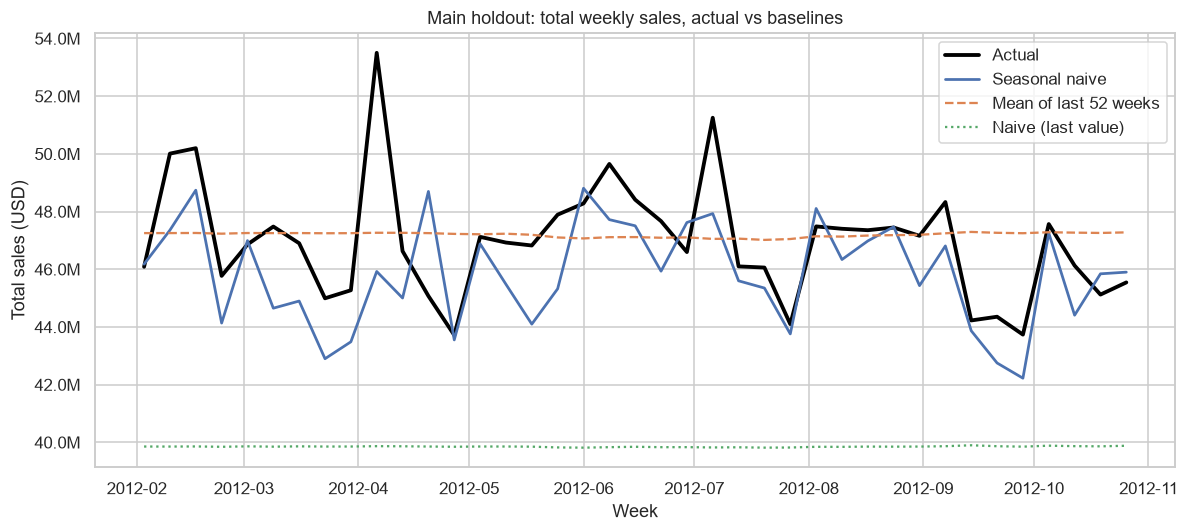

Seasonal naive total-sales bias over the holdout: -2.37%


In [21]:
# Aggregate view: total actual vs forecast sales per week
agg_cols = ["Weekly_Sales"] + list(MODELS.values())
agg = preds.groupby("Date")[agg_cols].sum()

fig, ax = plt.subplots()
ax.plot(agg.index, agg["Weekly_Sales"], lw=2.5, color="black", label="Actual")
ax.plot(agg.index, agg["pred_seasonal_naive"], lw=1.8, label="Seasonal naive")
ax.plot(agg.index, agg["pred_mean_52w"], lw=1.5, ls="--", label="Mean of last 52 weeks")
ax.plot(agg.index, agg["pred_naive_last"], lw=1.5, ls=":", label="Naive (last value)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Main holdout: total weekly sales, actual vs baselines")
ax.set_xlabel("Week")
ax.set_ylabel("Total sales (USD)")
ax.legend()
savefig("14_baseline_holdout_total")

bias = (agg["pred_seasonal_naive"].sum() - agg["Weekly_Sales"].sum()) / agg["Weekly_Sales"].sum() * 100
print(f"Seasonal naive total-sales bias over the holdout: {bias:+.2f}%")

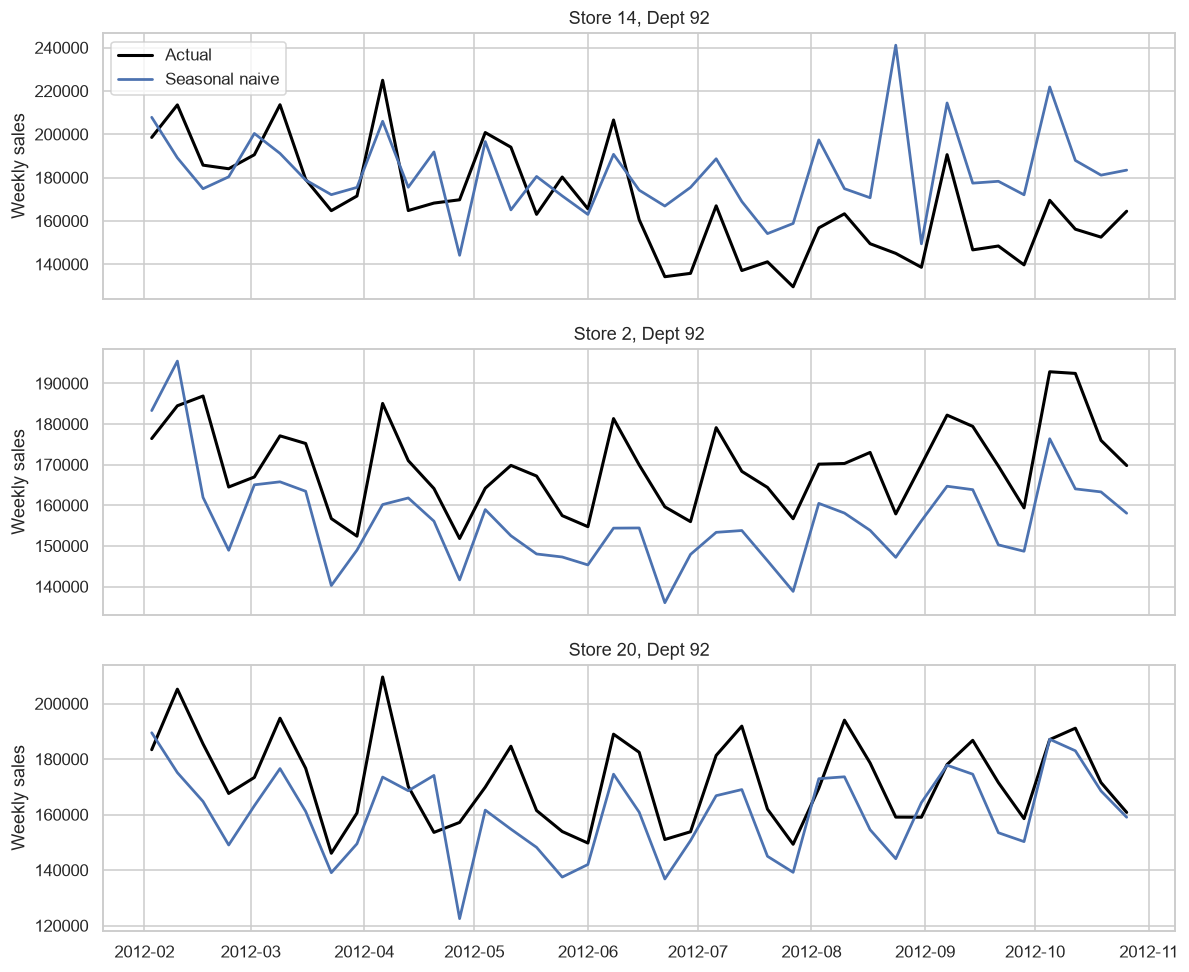

In [22]:
# Three individual series: the biggest store-department series in the training period
top_series = (train.groupby(["Store", "Dept"])["Weekly_Sales"].sum()
              .nlargest(3).index.tolist())

fig, axes = plt.subplots(len(top_series), 1, figsize=(11, 9), sharex=True)
for ax, (s, d) in zip(axes, top_series):
    sub = preds[(preds["Store"] == s) & (preds["Dept"] == d)].sort_values("Date")
    ax.plot(sub["Date"], sub["Weekly_Sales"], color="black", lw=2, label="Actual")
    ax.plot(sub["Date"], sub["pred_seasonal_naive"], lw=1.8, label="Seasonal naive")
    ax.set_title(f"Store {s}, Dept {d}")
    ax.set_ylabel("Weekly sales")
axes[0].legend()
savefig("15_baseline_top_series")

**Observations**
- Ranking by WMAE: Seasonal naive (best, 1,804.20) < Mean of last 52 weeks (2,420.27) < Naive last value (worst, 3,199.36). Seasonal naive has MAE 1,803.18, RMSE 3,858.52 and WMAE 1,804.20.
- Seasonal naive improves MAE over the simplest baseline (last value) by about 42%, and over the 52-week mean by about 24%.
- It used the same-week-last-year value for ___% of test rows; the rest used the fallback rule.
- The aggregate chart shows that seasonal naive ___ (tracks / misses) the weekly pattern, with a total bias of −2.37% (it under-forecasts total sales slightly over the 39 weeks).
- RMSE is about 2.1x MAE for seasonal naive (3,859 vs 1,803), meaning a small number of very large errors dominate. Large departments and spikes are the likely cause (checked below).
- WMAE is almost identical to MAE for seasonal naive (1,804 vs 1,803), but noticeably higher for the other two baselines (for example 3,199 vs 3,127 for last value). So seasonal naive handles the flagged holiday weeks (Super Bowl and Labor Day) as well as normal weeks, while the simpler baselines do worse in them. Note that only two flagged weeks fall in this window.

## 5. Where do the errors come from?


In [23]:
store_type = df[["Store", "Type"]].drop_duplicates()
p = preds.merge(store_type, on="Store", how="left")
p["abs_err"] = (p["Weekly_Sales"] - p["pred_seasonal_naive"]).abs()
p["month"] = p["Date"].dt.month

def breakdown(frame, by):
    g = frame.groupby(by).agg(rows=("abs_err", "size"), MAE=("abs_err", "mean"),
                              total_err=("abs_err", "sum"), total_sales=("Weekly_Sales", "sum"))
    g["WAPE_pct"] = g["total_err"] / g["total_sales"] * 100
    return g[["rows", "MAE", "WAPE_pct"]].round(2)

print("By store type:");               display(breakdown(p, "Type"))
print("By flagged holiday week:");     display(breakdown(p, "IsHoliday"))
print("By month:");                    display(breakdown(p, "month"))

By store type:


,rows,MAE,WAPE_pct
Type,,,
A,58893,2149.79,10.74
B,44764,1586.00,13.19
C,11931,907.10,9.47


By flagged holiday week:


,rows,MAE,WAPE_pct
IsHoliday,,,
0,109621,1802.86,11.40
1,5967,1809.11,10.98


By month:


,rows,MAE,WAPE_pct
month,,,
2,11946,1750.08,10.89
3,14850,1733.18,11.12
4,11889,2533.26,15.94
5,11822,1821.91,11.41
6,14753,1709.40,10.48
7,11798,1693.32,10.65
8,14801,1768.28,11.05
9,11854,1597.30,10.48
10,11875,1669.24,10.75


In [24]:
dept_err = p.groupby("Dept")["abs_err"].sum().sort_values(ascending=False)
share = (dept_err / dept_err.sum() * 100).round(2)
print(f"Top 10 departments account for {share.head(10).sum():.1f}% of all absolute error")
display(pd.DataFrame({"share_of_error_pct": share.head(10)}))

# Largest single errors
err_cols = ["Store", "Dept", "Date", "Weekly_Sales", "pred_seasonal_naive", "abs_err"]
print("Ten largest individual errors:")
display(p.nlargest(10, "abs_err")[err_cols].round(0))

Top 10 departments account for 39.4% of all absolute error


,share_of_error_pct
Dept,
38,6.89
92,6.31
72,5.11
95,4.18
1,3.69
90,2.88
16,2.69
7,2.65
5,2.56


Ten largest individual errors:


C:\Users\Welcome\AppData\Local\Temp\ipykernel_5924\3866833999.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(p.nlargest(10, "abs_err")[err_cols].round(0))


,Store,Dept,Date,Weekly_Sales,pred_seasonal_naive,abs_err
32115,13,1,2012-04-20,30201.0,154138.0,123937.0
51270,20,1,2012-04-20,24247.0,143221.0,118974.0
34960,14,1,2012-04-06,156677.0,41257.0,115420.0
34962,14,1,2012-04-20,18877.0,133745.0,114867.0
51268,20,1,2012-04-06,156234.0,55118.0,101116.0
32113,13,1,2012-04-06,150715.0,51890.0,98825.0
37452,14,92,2012-08-24,145010.0,241120.0,96110.0
37569,14,95,2012-08-24,113004.0,206434.0,93430.0
32213,13,3,2012-09-07,114231.0,27062.0,87168.0
23905,10,1,2012-04-20,26760.0,113432.0,86672.0


## 6. Holiday-season stress test
Training stops on **2011-10-28**. The test window is **2011-11-04 → 2012-01-27** (13 weeks), which contains Thanksgiving, the pre-Christmas peak and the flagged Christmas week. Training is shorter here (91 weeks), so every model has less history; use this window to compare models during the holiday season, not to compare absolute error levels with the main holdout.

In [25]:
train_b, test_b = split_by_date(df, "2011-11-04", "2012-01-27")
assert train_b["Date"].max() < test_b["Date"].min()
print(f"Train: {train_b['Date'].min().date()} -> {train_b['Date'].max().date()} ({train_b['Date'].nunique()} weeks)")
print(f"Test:  {test_b['Date'].min().date()} -> {test_b['Date'].max().date()} ({test_b['Date'].nunique()} weeks, {len(test_b):,} rows)")
print("Flagged holiday weeks in test:", sorted(test_b.loc[test_b["IsHoliday"] == 1, "Date"].dt.date.unique()))

preds_b = build_baseline_predictions(train_b, test_b)
print(f"Same-week-last-year used for {(~preds_b['used_fallback_sn']).mean() * 100:.1f}% of rows")

holiday_scores = score_table(preds_b)
display(holiday_scores)

Train: 2010-02-05 -> 2011-10-28 (91 weeks)
Test:  2011-11-04 -> 2012-01-27 (13 weeks, 38,798 rows)
Flagged holiday weeks in test: [datetime.date(2011, 11, 25), datetime.date(2011, 12, 30)]
Same-week-last-year used for 96.6% of rows


,model,MAE,RMSE,WMAE
0,Seasonal naive (52 weeks),2072.74,4708.38,2244.82
1,Mean of last 52 weeks,4051.65,12214.20,4707.62
2,Naive (last value),4089.57,12388.90,4766.56


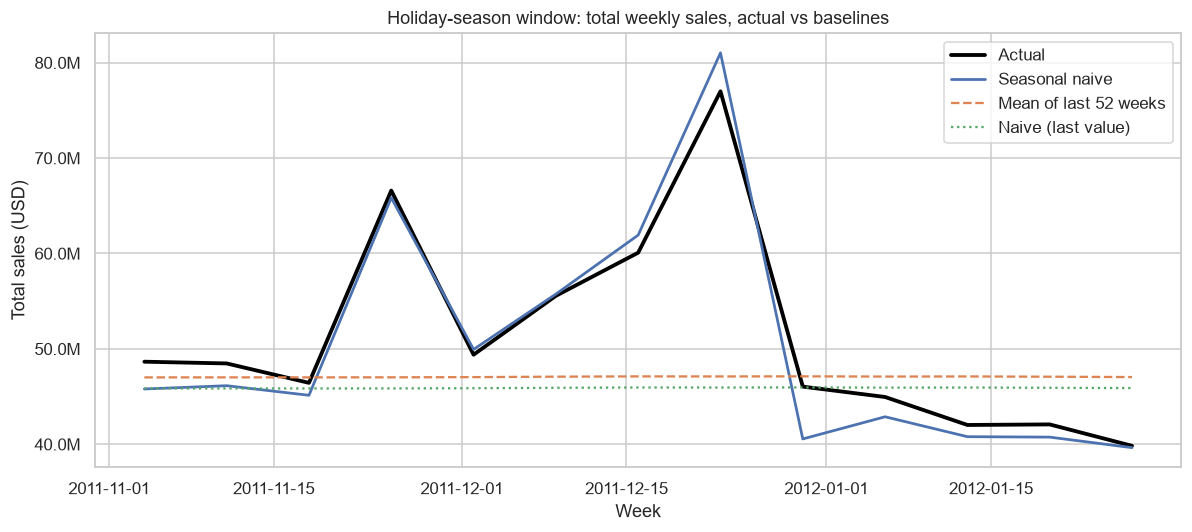

Seasonal-naive total-sales error per week (%):
Date
2011-11-04    -5.9
2011-11-11    -4.8
2011-11-18    -2.8
2011-11-25    -1.1
2011-12-02     1.1
2011-12-09     0.3
2011-12-16     3.1
2011-12-23     5.2
2011-12-30   -11.9
2012-01-06    -4.6
2012-01-13    -2.9
2012-01-20    -3.2
2012-01-27    -0.5


In [26]:
agg_b = preds_b.groupby("Date")[agg_cols].sum()

fig, ax = plt.subplots()
ax.plot(agg_b.index, agg_b["Weekly_Sales"], lw=2.5, color="black", label="Actual")
ax.plot(agg_b.index, agg_b["pred_seasonal_naive"], lw=1.8, label="Seasonal naive")
ax.plot(agg_b.index, agg_b["pred_mean_52w"], lw=1.5, ls="--", label="Mean of last 52 weeks")
ax.plot(agg_b.index, agg_b["pred_naive_last"], lw=1.5, ls=":", label="Naive (last value)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Holiday-season window: total weekly sales, actual vs baselines")
ax.set_xlabel("Week")
ax.set_ylabel("Total sales (USD)")
ax.legend()
savefig("16_baseline_holiday_total")

gap = (agg_b["pred_seasonal_naive"] - agg_b["Weekly_Sales"]) / agg_b["Weekly_Sales"] * 100
print("Seasonal-naive total-sales error per week (%):")
print(gap.round(1).to_string())

**Observations**
- In the holiday window the ranking is Seasonal naive < Mean of last 52 weeks < Naive (last value) by WMAE (2,244.82 < 4,707.62 < 4,766.56). Seasonal naive has WMAE 2,244.82 versus 4,766.56 for the last-value baseline, a 53% improvement (49% on MAE). This is larger than the roughly 44% improvement on the main holdout, because the last value and the 52-week mean cannot anticipate the holiday spike; the two are almost equally poor here (WMAE 4,708 vs 4,767, RMSE above 12,000).
- Seasonal naive tracks the Thanksgiving and pre-Christmas peaks because it reuses the same weeks from last year, with weekly total errors between −11.9% and +5.2%, and within ±6% in 12 of the 13 weeks. Thanksgiving week (2011-11-25) is off by only −1.1%.
- The weeks where it misses most are the flagged Christmas week (2011-12-30, −11.9%) and the pre-Christmas week (2011-12-23, +5.2%). Weak points:
  - The reference week for 2011-12-30 is 2010-12-31, which was unusually weak (40.4M versus 46.0M actual a year later), so the forecast is too low. This week is flagged, so it carries 5x weight in WMAE, which is why WMAE (2,245) is higher than MAE (2,073) here.
  - The 2011 pre-Christmas peak (77.0M) was lower than the 2010 one (80.9M), so reusing last year's week over-forecasts.
  - Nine of 13 weeks are under-forecast (average error about −2.2%), consistent with the −2.4% bias on the main holdout. The model reuses last year's level and misses year-over-year growth.
  - About 3.4% of rows have no same-week-last-year value and use the fallback rule.


## 7. Saving results and summary


In [27]:
results = pd.concat([
    holdout_scores.assign(window="Main holdout (39 wks)"),
    holiday_scores.assign(window="Holiday stress test (13 wks)"),
], ignore_index=True)[["window", "model", "MAE", "RMSE", "WMAE"]]

results.to_csv(REPORTS / "baseline_results.csv", index=False)
preds.to_parquet(PROCESSED / "baseline_predictions_holdout.parquet", index=False)
display(results)
print("Saved: reports/baseline_results.csv and data/processed/baseline_predictions_holdout.parquet")

,window,model,MAE,RMSE,WMAE
0,Main holdout (39 wks),Seasonal naive (52 weeks),1803.18,3858.52,1804.20
1,Main holdout (39 wks),Mean of last 52 weeks,2371.89,4911.09,2420.27
2,Main holdout (39 wks),Naive (last value),3126.65,6330.77,3199.36
3,Holiday stress test (13 wks),Seasonal naive (52 weeks),2072.74,4708.38,2244.82
4,Holiday stress test (13 wks),Mean of last 52 weeks,4051.65,12214.20,4707.62
5,Holiday stress test (13 wks),Naive (last value),4089.57,12388.90,4766.56


Saved: reports/baseline_results.csv and data/processed/baseline_predictions_holdout.parquet


### Summary
- **Setup:** 39-week forecast horizon; train ≤ 2012-01-27, test 2012-02-03 → 2012-10-26 (115,588 rows). A second 13-week holiday window (train ≤ 2011-10-28, test 2011-11-04 → 2012-01-27, 38,798 rows) checks Thanksgiving/Christmas behaviour.
- **Best baseline:** seasonal naive (WMAE 1,804.20, MAE 1,803.18, RMSE 3,858.52 on the main holdout; WMAE 2,244.82 in the holiday window). It beats the 52-week mean and last-value baselines in both windows, by about 24% and 42% on the main holdout MAE and by about 49% in the holiday window.
- **Target for notebook 04:** Random Forest and Gradient Boosting (and ETS/ARIMA) must beat these numbers on the same two windows.
- **Important constraint:** because the horizon is 39 weeks, features must be at least 39 weeks old at forecast time (for example `lag_52`, same-week-last-year averages, store and department averages from the training period, calendar and holiday features). Lag 1/2/4 features are not allowed in this setup.
- **Known weak spots:**
  - The flagged Christmas week (2011-12-30) is the worst week (−11.9% on total sales) because the reference week a year earlier was unusually weak, and it carries 5x weight in WMAE.
  - A slight under-forecast (−2.37% total bias on the main holdout) because last year's level misses year-over-year growth.
  - RMSE is about 2x MAE, so a small number of large errors dominate.
  - A small share of rows have no same-week-last-year value and rely on the fallback rule (2.7% on the main holdout, 3.4% in the holiday window).